# Regressions and moving average with stat_tool

## This notebook illustates how to perform regression and moving average with stat_tool.regression

Load a data set (chene_sessile.vec)    

In [1]:
from openalea.stat_tool import get_shared_data
from openalea.stat_tool.regression import Regression
from openalea.stat_tool.vectors import Vectors


vec = Vectors(get_shared_data("chene_sessile.vec"))

Running cmake --build & --install in /home/jdurand/devlp/Git/openalea/stat_tool/build
Running cmake --build & --install in /home/jdurand/devlp/Git/openalea/sequence_analysis/build


### Plot component 3 of vec as a function of component 2

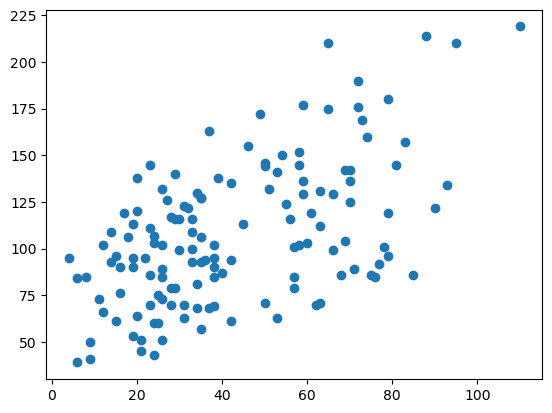

In [2]:
import matplotlib.pyplot as plt

plt.scatter(vec.select_variable([2], True), vec.select_variable([3], True), )

### Linear regression: predict component 3 of vec from component 2 (Least square)

In [3]:
r1 = Regression(vec, "Linear", 2, 3)
print(r1)

138 vectors

explanatory variable   (minimum value: 4, maximum value: 110)

marginal frequency distribution - sample size: 138
mean: 42.8043   median: 37   mode: 26
variance: 539.064   standard deviation: 23.2177   lower quartile: 24   upper quartile: 61

response variable   (minimum value: 39, maximum value: 219)

marginal frequency distribution - sample size: 138
mean: 107.725   median: 102   mode: 85
variance: 1424.04   standard deviation: 37.7365   lower quartile: 84   upper quartile: 131

correlation coefficient: 0.557942

intercept: 68.908 (standard deviation: 5.62756)   57.7792 <= intercept <= 80.0369
two-sided t-test (136 degrees of freedom)
t-value: 12.2447   critical probability: 1.06255e-23
reference t-value: 1.97756   reference critical probability: 0.05
reference t-value: 2.61246   reference critical probability: 0.01

slope: 0.906838 (standard deviation: 0.115661)   0.678112 <= slope <= 1.13557
two-sided t-test (136 degrees of freedom)
t-value: 7.84048   critical probabil

### Plot result

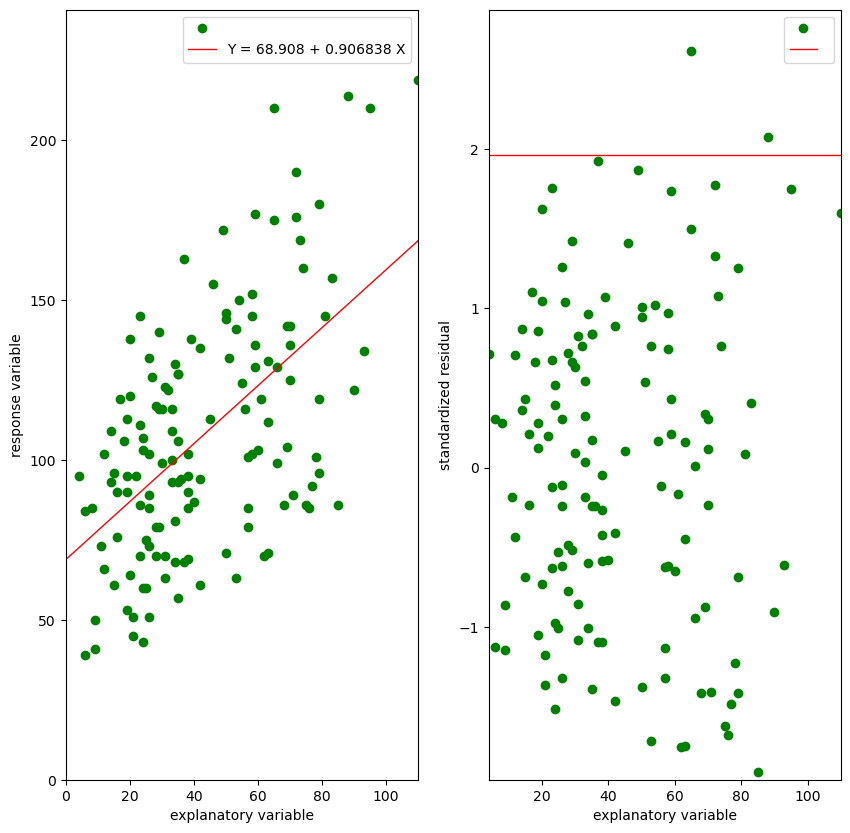

In [4]:
r1.plot()

The left-hand side plot represents the linear regression (point cloud and least square line); the right-hand side plot represents the residuals as a function of the explanatory variable. The model assumes that the residuals are independent with a variance that does not depend on the explanatory variable, which seems to be the case here.

The equivalent object-oriented syntax is:

In [5]:
vec.linear_regression(2,3)

## Variant 1: nearest neighbours regression

Nearest neighbours regression consists in predicting the value of the response variable using a weighted mean of its neighbours. The number of neighbours is determined as a fraction of the sample size, here 0.1.

In [6]:
r2 = Regression(vec, "NearestNeighbors", 2, 3, 0.1)
print(r2) 

138 vectors

explanatory variable   (minimum value: 4, maximum value: 110)

marginal frequency distribution - sample size: 138
mean: 42.8043   median: 37   mode: 26
variance: 539.064   standard deviation: 23.2177   lower quartile: 24   upper quartile: 61

response variable   (minimum value: 39, maximum value: 219)

marginal frequency distribution - sample size: 138
mean: 107.725   median: 102   mode: 85
variance: 1424.04   standard deviation: 37.7365   lower quartile: 84   upper quartile: 131

coefficient of determination: 0.381148
17.5491 regression degrees of freedom   117.541 residual degrees of freedom

residual mean: -0.123864   residual standard deviation: 32.0491



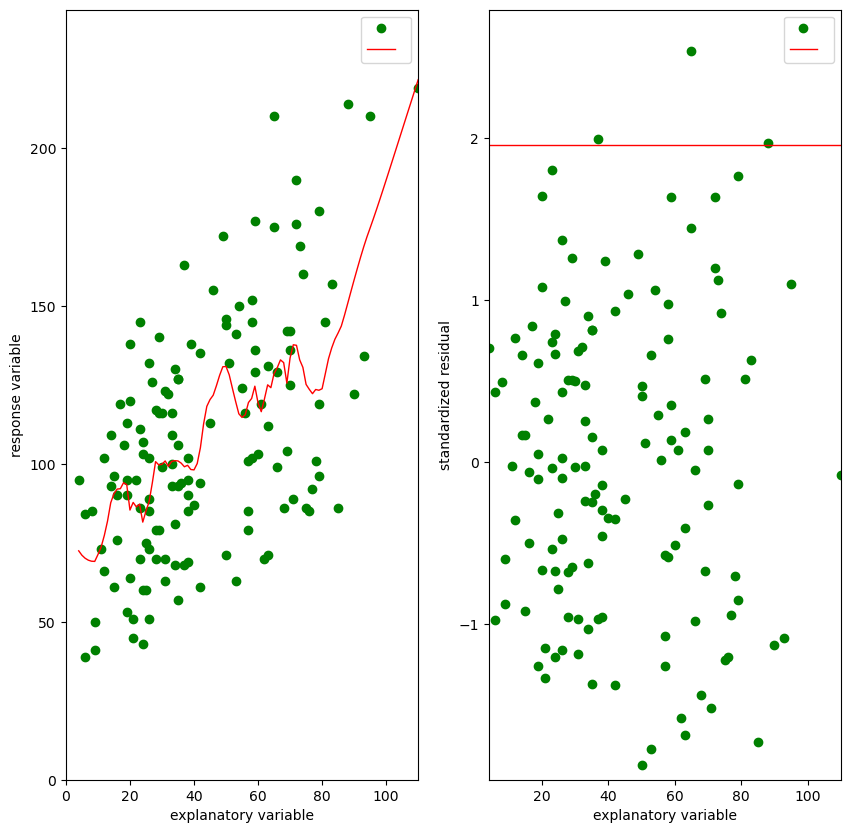

In [7]:
r2.plot()

The equivalent object-oriented syntax is:

In [8]:
vec.nearest_neighbours_regression(2, 3, 0.1, True)

The last argument (True, here) corresponds to weighting or not of the neighbours according to their distance to
the computed point.

## Variant 2: moving average

Moving average regression consists in predicting the value of the response variable using a weighted mean of the previous and future values. The weights are symmetric and provided as an argument, here the probability mass function of a Binomial(0, 4, 0.5).

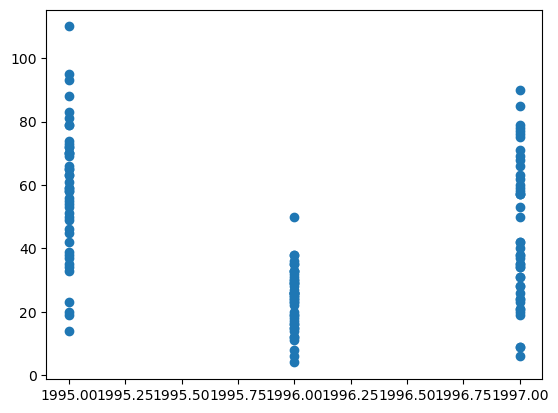

In [9]:
plt.scatter(vec.select_variable([1], True), vec.select_variable([2], True))

In [10]:
from openalea.stat_tool.compound import Compound
from openalea.stat_tool.distribution import Binomial
r3 = Regression(vec, "MovingAverage", 1, 2, Binomial(0, 4, 0.5))
print(r3) 

138 vectors

explanatory variable   (minimum value: 1995, maximum value: 1997)

marginal frequency distribution - sample size: 138
mean: 1996   median: 1996   mode: 1996
variance: 0.671533   standard deviation: 0.819471   lower quartile: 1995   upper quartile: 1997

response variable   (minimum value: 4, maximum value: 110)

marginal frequency distribution - sample size: 138
mean: 42.8043   median: 37   mode: 26
variance: 539.064   standard deviation: 23.2177   lower quartile: 24   upper quartile: 61

coefficient of determination: 0.214708
2.42857 regression degrees of freedom   135.49 residual degrees of freedom

residual mean: -5.31056   residual standard deviation: 19.9829



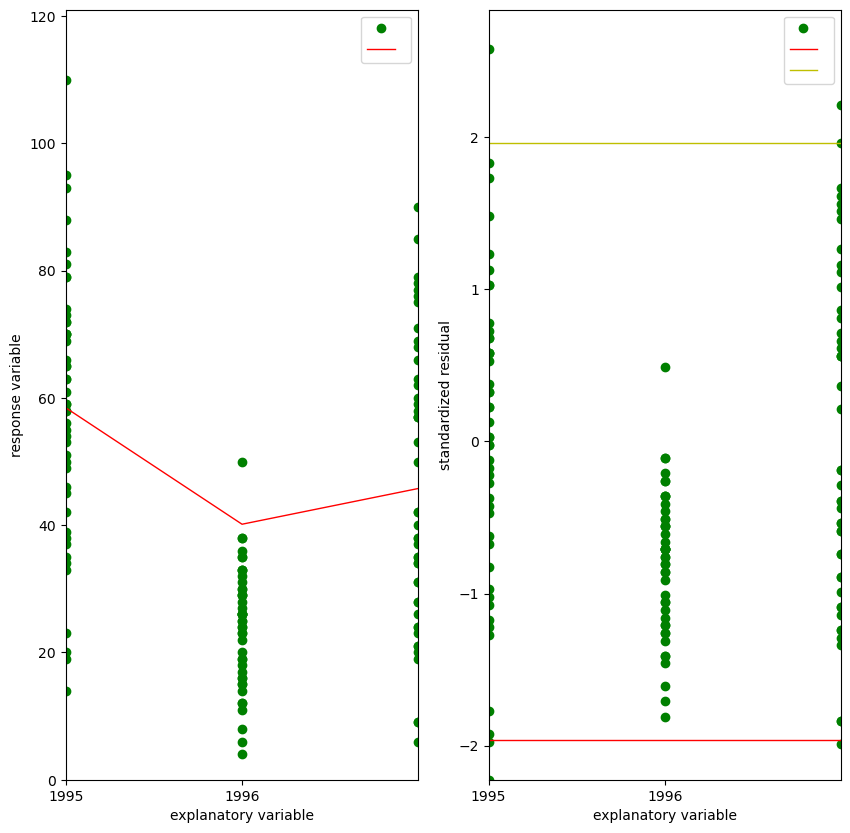

In [11]:
r3.plot()

The equivalent object-oriented syntax is:

In [12]:
from openalea.stat_tool.enums import algo_map
vec.moving_average_regression_distribution(1, 2, Binomial(0, 4, 0.5), algo=algo_map["Averaging"])

The last argument ("Averaging", here) corresponds standard moving average filtering; as an alternative, "LeastSquares" implements the least squares moving average regression, where a linear regression is fit locally using the last previous points.